# Практическое занятие № 21 — Повышение качества и сравнение нейросетевых моделей
**ТюмГУ · Технологии искусственного интеллекта — 1 · 90 минут**  
Автор учебных материалов: В. А. Мазур, доцент ШКН ТюмГУ.

**Задача:** на одном временном разбиении сравнить простую модель, градиентный бустинг и несколько MLP; проверить роль `dropout`, `weight_decay`, `early stopping`, разброс по нескольким seed, качество вероятностей и стоимость ошибок.  
**На выходе:** `results_21_bundle.zip` с моделями, журналом экспериментов, метриками, схемой входов, протоколом разделения и README для занятия 22.

Внимание: если в каталоге есть `orders_dirty.csv`, используется он. Иначе блокнот создаёт **отдельные синтетические демонстрационные данные**; метрики на них не являются измерениями основного учебного набора.  
**Запрещено:** включать в `X` `actual_minutes`, `late`, `order_id`, обучать импутер/масштабирование на validation/test, подбирать архитектуру или порог на test.

## 1. Организация эксперимента и зависимости (0–10 мин)

Зафиксируйте среду, seed, критерии выбора и ограничения. В этой работе checkpoint выбирается по минимальному `validation BCE`; **архитектура** — по среднему `Average Precision` на validation с учётом разброса и затрат; порог — на validation по *учебной* функции стоимости `60·FP + 300·FN`. Условия не являются экономическими данными реального перевозчика.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,zipfile,copy,platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss, brier_score_loss, precision_score, recall_score, f1_score, confusion_matrix
import sklearn, joblib
from IPython.display import display, Image
STUDENT='Сидоров'; GROUP='нет'; DATE='2026-11-24'
SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(2, max(1, os.cpu_count() or 1)))
ROOT=Path('results_21'); ROOT.mkdir(exist_ok=True)
print('Студент:',STUDENT,'группа:',GROUP,'дата:',DATE)
print('Python',sys.version.split()[0],'PyTorch',torch.__version__,'NumPy',np.__version__,'pandas',pd.__version__,'sklearn',sklearn.__version__)
print('Устройство: CPU; результаты разных CPU/GPU могут немного различаться.')

Студент: Сидоров группа: нет дата: 2026-11-24
Python 3.12.14 PyTorch 2.15.0+cpu NumPy 2.2.5 pandas 2.2.3 sklearn 1.9.1
Устройство: CPU; результаты разных CPU/GPU могут немного различаться.


## 2. Данные, дефекты и граница времени (10–22 мин)

Единица наблюдения — заказ. `late=1`, если фактическое время доставки превышает обещанное более чем на 15 минут. Для проверки исторической метки можно временно использовать `actual_minutes`, но в признаки его включать нельзя.

- Удаляйте только **точные дубликаты**; конфликтные метки исключайте с зафиксированным обоснованием.
- Если один `order_id` обозначает несколько разных строк, нельзя молча удалять их; здесь эксперимент останавливается до разрешения конфликта.
- Разбивайте по `created_at` на 60/20/20; train, validation и test никогда не перемешивайте между собой.
- Студенческий файл не изменяйте.

In [2]:
def demo_data(n=600,seed=2026):
    rng=np.random.default_rng(seed)
    created=pd.date_range('2026-01-01',periods=n,freq='3h')
    distance=rng.uniform(1,28,n)
    queue=rng.poisson(11,n).astype(float)
    promised=rng.integers(30,95,n).astype(float)
    weather=rng.choice(['clear','rain','snow'],size=n,p=[.62,.28,.10])
    zone=rng.choice(['center','north','south','east'],size=n)
    effective=distance*1.7+queue*1.1+np.where(weather=='snow',20,np.where(weather=='rain',9,0)) + (zone=='center')*7+rng.normal(0,16,n)+16
    actual=np.maximum(5,np.rint(effective))
    label=(actual-promised>15).astype(int)
    frame=pd.DataFrame({'order_id':[f'DMO-{i:05d}' for i in range(n)],'created_at':created,
      'distance_km':distance.round(2),'queue_size':queue,'promised_minutes':promised,
      'actual_minutes':actual,'weather':weather,'zone':zone,'late':label})
    frame.loc[9,'distance_km']='нет данных'
    frame.loc[20,'weather']=None
    frame.loc[44,'queue_size']=np.nan
    # Демонстрационные дефекты: один полный повтор и одна противоречивая историческая метка
    frame.loc[61,'late']=1-int(frame.loc[61,'late'])
    return pd.concat([frame,frame.iloc[[17]]],ignore_index=True)
source=Path('orders_dirty.csv')
assert source.exists(),'Для основной работы требуется orders_dirty.csv из предыдущих занятий'
raw=pd.read_csv(source,encoding='utf-8-sig')
origin='orders_dirty.csv / основной учебный источник из предыдущих работ; НЕ demo_orders_21_22.csv'
raw_count=len(raw);duplicate_count=int(raw.duplicated().sum())
print(origin,'сырой размер',raw.shape,'дубли строк',raw.duplicated().sum())
required=['order_id','created_at','late','distance_km','queue_size','promised_minutes','weather','zone']
missing=[c for c in required if c not in raw.columns]
assert not missing,f'Отсутствуют обязательные столбцы: {missing}. Сверьте словарь полей и измените адаптер.'
work=raw.drop_duplicates().copy()
work['created_at']=pd.to_datetime(work['created_at'],errors='coerce')
comma_count=int(work.distance_km.astype('string').str.contains(',',regex=False,na=False).sum())
work['distance_km']=pd.to_numeric(work.distance_km.astype('string').str.replace(',','.',regex=False),errors='coerce')
for col in ['queue_size','promised_minutes']:
    work[col]=pd.to_numeric(work[col],errors='coerce')
for col in ['distance_km','queue_size','promised_minutes']:
    work.loc[work[col]<0,col]=np.nan
work['late']=pd.to_numeric(work['late'],errors='coerce')
invalid=work['created_at'].isna() | ~work['late'].isin([0,1])
invalid_count=int(invalid.sum())
print('Строк без корректной даты/метки:',invalid_count)
work=work.loc[~invalid].copy()
mismatch_count=0
if 'actual_minutes' in work:
    actual=pd.to_numeric(work['actual_minutes'],errors='coerce')
    promised=work['promised_minutes']
    check=actual.notna() & promised.notna()
    mismatch=check & (((actual-promised)>15).astype(int)!=work['late'].astype(int))
    mismatch_count=int(mismatch.sum())
    print('Несогласованность исторической метки с правилом >15:',mismatch_count)
    work=work.loc[~mismatch].copy()
if work.order_id.duplicated().any():
    raise ValueError('Есть разные записи с одним order_id. Разрешите конфликт по исходному журналу до обучения.')
work=work.sort_values(['created_at','order_id']).reset_index(drop=True)
assert len(work)>=60, 'Недостаточно заказов для демонстрации трёх выборок'
a=int(.6*len(work)); b=a+int(.2*len(work))  # те же границы, что в lb20: 358/119/121
train,val,test=work.iloc[:a].copy(),work.iloc[a:b].copy(),work.iloc[b:].copy()
assert set(train.order_id).isdisjoint(val.order_id) and set(train.order_id).isdisjoint(test.order_id) and set(val.order_id).isdisjoint(test.order_id)
assert train.created_at.max()<=val.created_at.min()<=test.created_at.min()
assert all(v['late'].nunique()==2 for v in [train,val,test]),'В одной из частей один класс — нужен другой достаточный набор/валидный протокол.'
splits=pd.concat([z.assign(part=k)[['order_id','created_at','late','part']] for k,z in [('train',train),('validation',val),('test',test)]])
splits.to_csv(ROOT/'split_membership.csv',index=False)
split_stats=splits.groupby('part')['late'].agg(['size','sum','mean'])
display(split_stats)
audit_table=pd.DataFrame([
    ('Полный дубль',duplicate_count,'Повтор одной и той же записи не должен влиять на обучение'),
    ('Недопустимая дата или метка',invalid_count,'Нельзя однозначно включить в хронологию или классификацию'),
    ('Конфликт late с правилом >15 минут',mismatch_count,'Историческая метка противоречит фактическому и обещанному времени')],
    columns=['что исключено','сколько','почему'])
display(audit_table)
print('До/после:',raw_count,len(work),'строк; десятичных запятых distance_km исправлено:',comma_count)
dictionary=pd.read_csv('data_dictionary.csv')
field_provenance=dictionary.loc[dictionary.field.isin(['distance_km','queue_size','promised_minutes','weather','zone','actual_minutes','late','order_id','created_at']),
 ['field','known_at','model_usage']]
display(field_provenance)
assert len(work)==raw_count-duplicate_count-invalid_count-mismatch_count
assert work.order_id.is_unique and work.created_at.notna().all()

orders_dirty.csv / основной учебный источник из предыдущих работ; НЕ demo_orders_21_22.csv сырой размер (600, 10) дубли строк 1
Строк без корректной даты/метки: 0
Несогласованность исторической метки с правилом >15: 1


,size,sum,mean
part,,,
test,121,66,0.545455
train,358,161,0.449721
validation,119,53,0.445378


,что исключено,сколько,почему
0,Полный дубль,1,Повтор одной и той же записи не должен влиять ...
1,Недопустимая дата или метка,0,Нельзя однозначно включить в хронологию или кл...
2,Конфликт late с правилом >15 минут,1,Историческая метка противоречит фактическому и...


До/после: 600 598 строк; десятичных запятых distance_km исправлено: 1


,field,known_at,model_usage
0,order_id,при создании,не использовать как X
1,created_at,при создании,для хронологического разбиения; производные пр...
2,distance_km,при создании,X
3,queue_size,при создании,X
4,weather,при создании,X
5,zone,при создании,X
6,promised_minutes,при создании,X
7,actual_minutes,после доставки,НЕ X; только контроль late
8,late,после доставки,y; аудит против расчетного значения


## 3. Безопасная предобработка и сравнимые baseline (22–33 мин)

Препроцессор `fit` только на train. Категории из validation и test не должны обучать one-hot. Сравнение выполняется на одинаковых матрицах признаков. Включён DummyClassifier (`strategy="prior"`) как константный базовый вероятностный прогноз, а также LogReg и бустинг.

In [3]:
NUM=['distance_km','queue_size','promised_minutes'];CAT=['weather','zone']
FEATURES=NUM+CAT
assert not set(FEATURES) & {'late','actual_minutes','order_id','created_at'}
for subset in [train,val,test]:
    for c in CAT: subset[c]=subset[c].astype(object).where(subset[c].notna(),np.nan)
try: enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError: enc=OneHotEncoder(handle_unknown='ignore',sparse=False)
prep=ColumnTransformer([
 ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scale',StandardScaler())]),NUM),
 ('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',enc)]),CAT)
],remainder='drop',sparse_threshold=0)
Xtr=np.asarray(prep.fit_transform(train[FEATURES]),dtype=np.float32)
Xva=np.asarray(prep.transform(val[FEATURES]),dtype=np.float32)
ytr=train.late.to_numpy(dtype=np.int64); yva=val.late.to_numpy(dtype=np.int64)
print('Матрицы train / val:',Xtr.shape,Xva.shape,'test НЕ преобразован и НЕ оценён')
models={'Dummy':DummyClassifier(strategy='prior'), 'LogReg':LogisticRegression(max_iter=1000,random_state=42),
 'Boosting':GradientBoostingClassifier(n_estimators=70,max_depth=2,random_state=42)}
for model in models.values():model.fit(Xtr,ytr)
base_probs={name:model.predict_proba(Xva)[:,list(model.classes_).index(1)] for name,model in models.items()}
baseline_ap=pd.DataFrame([{'model':name,'validation_AP':average_precision_score(yva,p)} for name,p in base_probs.items()])
display(baseline_ap.round(4))
assert np.isfinite(Xtr).all() and np.isfinite(Xva).all()
assert Xtr.dtype==Xva.dtype==np.float32
print('Число входных столбцов после one-hot:',Xtr.shape[1],'; test не преобразован')

Матрицы train / val: (358, 10) (119, 10) test НЕ преобразован и НЕ оценён


,model,validation_AP
0,Dummy,0.4454
1,LogReg,0.7367
2,Boosting,0.7033


Число входных столбцов после one-hot: 10 ; test не преобразован


## 4. MLP, регуляризация и ранняя остановка (33–55 мин)

Реализуйте контролируемые варианты с одинаковой схемой входов и разбиением. `nn.BCEWithLogitsLoss` получает **логиты**; вероятности нужны только для отчёта. `deepcopy(model.state_dict())` сохраняет лучший checkpoint, а `model.eval()` и `torch.no_grad()` обеспечивают корректную оценку.

$$t^*=\arg\min_{1\le t\le T}L_{val}(\theta_t),\quad P_{linear}=d_{in}\cdot d_{out}+d_{out}$$

**Сравнение:** базовая MLP 16–16 без dropout/weight decay; та же сеть с регуляризацией; сеть 32–32 с регуляризацией. Три `seed` показывают разброс; большего для серьёзного статистического вывода недостаточно.

In [4]:
class DeliveryMLP(nn.Module):
    def __init__(self,d,width=16,dropout=0.):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(d,width),nn.ReLU(),nn.Dropout(dropout),
                              nn.Linear(width,width),nn.ReLU(),nn.Dropout(dropout),nn.Linear(width,1))
    def forward(self,x):return self.net(x).squeeze(1)

assert sum(p.numel() for p in DeliveryMLP(20,16).parameters())==625
assert sum(p.numel() for p in DeliveryMLP(20,32).parameters())==1761
print('Проверка учебных размерностей 20→16→16→1: 625; 20→32→32→1: 1761')

def train_once(config,seed):
    torch.manual_seed(seed)
    rng=torch.Generator().manual_seed(seed)
    model=DeliveryMLP(Xtr.shape[1],config['width'],config['dropout'])
    loss_fn=nn.BCEWithLogitsLoss()
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    train_loader=DataLoader(TensorDataset(torch.as_tensor(Xtr),torch.as_tensor(ytr,dtype=torch.float32)),
                          batch_size=48,shuffle=True,generator=rng)
    val_x=torch.as_tensor(Xva);val_y=torch.as_tensor(yva,dtype=torch.float32)
    best=np.inf; best_state=None; best_epoch=0; bad=0; hist=[]
    started=time.perf_counter()
    for ep in range(1,config['epochs']+1):
        model.train();total=0
        for xb,yb in train_loader:
            optimizer.zero_grad(set_to_none=True)
            l=loss_fn(model(xb),yb);l.backward();optimizer.step();total+=l.item()*len(yb)
        train_loss=total/len(Xtr)
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(val_x),val_y).item())
        hist.append({'epoch':ep,'train_bce':train_loss,'val_bce':val_loss})
        if val_loss < best-config['min_delta']:
            best=val_loss;best_state=copy.deepcopy(model.state_dict());best_epoch=ep;bad=0
        else:
            bad+=1
        if bad >= config['patience']:break
    assert best_state is not None
    model.load_state_dict(best_state);model.eval()
    with torch.no_grad(): probs=torch.sigmoid(model(val_x)).cpu().numpy()
    elapsed=time.perf_counter()-started
    return model,probs,pd.DataFrame(hist),best_epoch,best,elapsed

configs={
  'MLP_16_plain':dict(width=16,dropout=0.,weight_decay=0.,lr=.001,epochs=50,patience=8,min_delta=.0005),
  'MLP_16_reg':dict(width=16,dropout=.2,weight_decay=.001,lr=.001,epochs=50,patience=8,min_delta=.0005),
  'MLP_32_reg':dict(width=32,dropout=.2,weight_decay=.001,lr=.001,epochs=50,patience=8,min_delta=.0005)}
seeds=[13,29,47]
rows=[];runs={}
for name,cfg in configs.items():
    for seed in seeds:
        model,pred,hist,epoch,loss,sec=train_once(cfg,seed)
        ap=average_precision_score(yva,pred)
        row={'model':name,'seed':seed,'val_AP':ap,'val_BCE':loss,'best_epoch':epoch,'epochs_run':len(hist),'seconds_cpu':sec,
             'n_parameters':sum(p.numel() for p in model.parameters())}
        rows.append(row);runs[(name,seed)]={'model':model,'probs':pred,'history':hist,'row':row}
experiments=pd.DataFrame(rows)
display(experiments.round(4))
assert len(experiments)==9 and set(experiments.seed)=={13,29,47}
print('Средние AP по архитектурам:');display(experiments.groupby('model').val_AP.agg(['mean','std']).round(4))
lr_config=dict(configs['MLP_16_reg']);lr_config['lr']=3e-4
lr_rows=[]
for seed in seeds:
    lr_model,lr_pred,lr_history,lr_epoch,lr_loss,lr_sec=train_once(lr_config,seed)
    lr_rows.append({'model':'MLP_16_reg_lr_3e-4','seed':seed,'val_AP':average_precision_score(yva,lr_pred),
        'val_BCE':lr_loss,'best_epoch':lr_epoch,'epochs_run':len(lr_history),'seconds_cpu':lr_sec,
        'n_parameters':sum(q.numel() for q in lr_model.parameters())})
lr_experiment=pd.DataFrame(lr_rows)
print('Дополнительный опыт: меняется только learning rate, архитектура и split прежние')
display(lr_experiment.round(4))

Проверка учебных размерностей 20→16→16→1: 625; 20→32→32→1: 1761


,model,seed,val_AP,val_BCE,best_epoch,epochs_run,seconds_cpu,n_parameters
0,MLP_16_plain,13,0.7228,0.6078,25,33,0.1975,465
1,MLP_16_plain,29,0.7261,0.6054,31,39,0.2448,465
2,MLP_16_plain,47,0.7332,0.6071,28,36,0.2086,465
3,MLP_16_reg,13,0.7243,0.6043,28,36,0.2486,465
4,MLP_16_reg,29,0.7250,0.6033,35,43,0.2663,465
5,MLP_16_reg,47,0.7358,0.6073,36,44,0.3143,465
6,MLP_32_reg,13,0.7206,0.6121,24,32,0.2007,1441
7,MLP_32_reg,29,0.7182,0.6129,22,30,0.1848,1441
8,MLP_32_reg,47,0.7247,0.6025,18,26,0.1640,1441


Средние AP по архитектурам:


,mean,std
model,,
MLP_16_plain,0.7274,0.0053
MLP_16_reg,0.7283,0.0064
MLP_32_reg,0.7211,0.0033


Дополнительный опыт: меняется только learning rate, архитектура и split прежние


,model,seed,val_AP,val_BCE,best_epoch,epochs_run,seconds_cpu,n_parameters
0,MLP_16_reg_lr_3e-4,13,0.7072,0.6205,50,50,0.3114,465
1,MLP_16_reg_lr_3e-4,29,0.6866,0.6661,50,50,0.3405,465
2,MLP_16_reg_lr_3e-4,47,0.7324,0.6298,50,50,0.3016,465


## 5. Графики, метрики и цена ошибок (55–72 мин)

Для повторных seed сравнивайте среднее и разброс; не заявляйте статистически доказанное превосходство по разнице 0,002. Здесь для учебного выбора архитектуры используем **средний AP на validation**; внутри выбранной архитектуры выбираем запуск с наименьшей `val_BCE`. Порог определяем **после этого**, только на validation.

$$AP=\sum_n (R_n-R_{n-1})P_n,\quad C(\tau)=60FP(\tau)+300FN(\tau)$$

Уточнение: AP из scikit-learn не равен автоматически трапециевидной площади PR-кривой. Цены 60/300 ₽ — именно **сценарий данной лекции**, а не проверенные хозяйственные расходы.

Выбранный для демонстрации checkpoint: MLP_16_reg seed 29


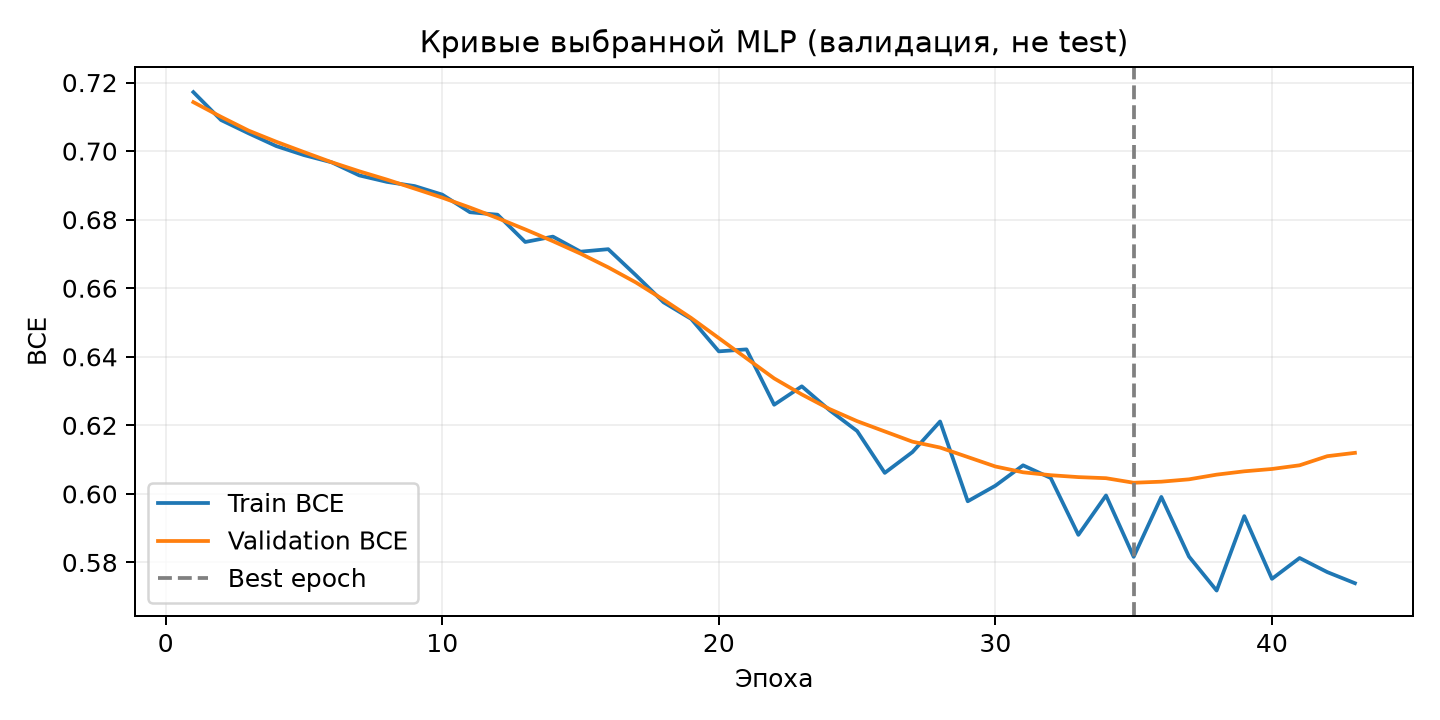

,model,threshold,AP,Brier,F1,FP,FN,cost_per_100_rub,alert_share
0,Dummy,0.00,0.4454,0.2470,0.6163,66,0,3327.7311,1.0000
1,LogReg,0.15,0.7367,0.2106,0.6463,58,0,2924.3697,0.9328
2,Boosting,0.00,0.7033,0.2347,0.6163,66,0,3327.7311,1.0000
3,MLP_selected,0.20,0.7250,0.2082,0.6310,62,0,3126.0504,0.9664


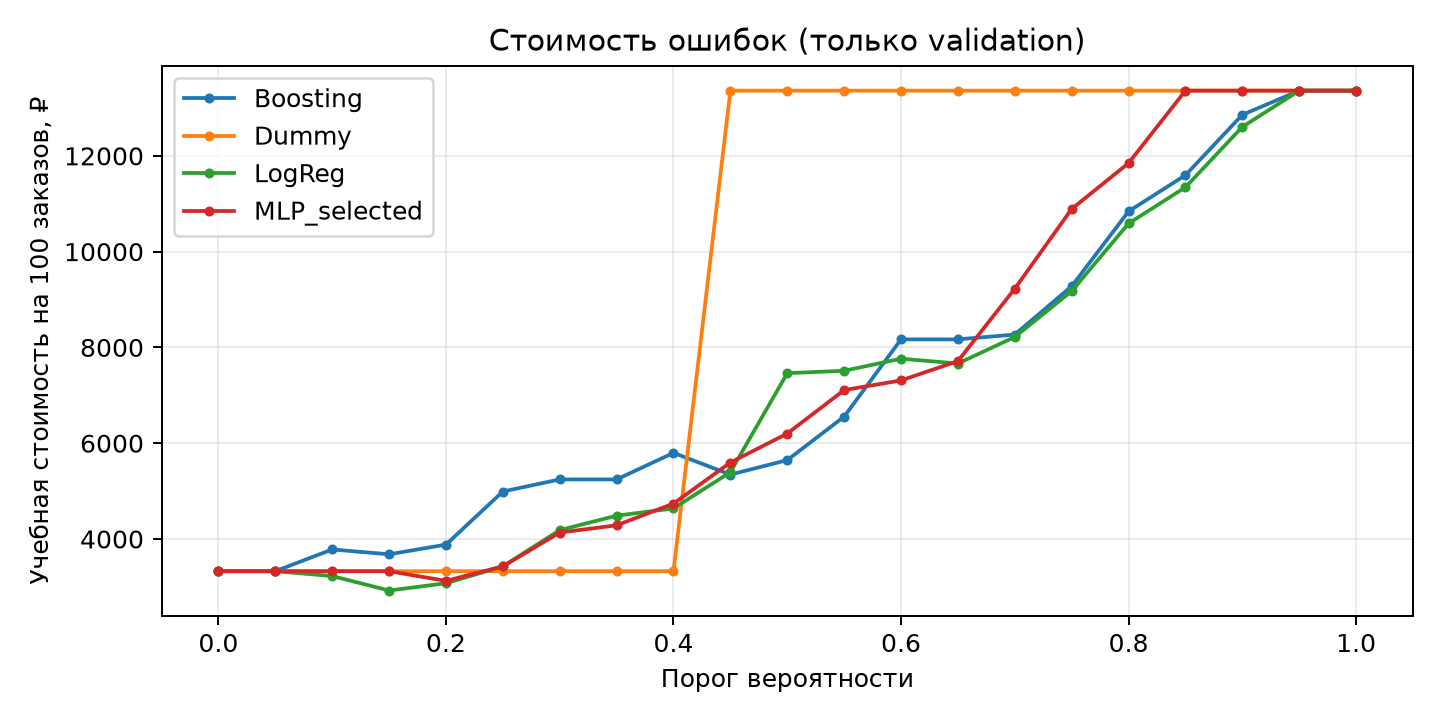

Единая таблица девяти запусков: метрики и условная стоимость на validation


,model,seed,n_parameters,AP_mean,AP_std,val_AP,val_BCE,seconds_cpu,cost_per_100_rub,threshold,FP,FN
0,MLP_16_plain,13,465,0.7274,0.0053,0.7228,0.6078,0.1975,3075.6303,0.20,56,1
1,MLP_16_plain,29,465,0.7274,0.0053,0.7261,0.6054,0.2448,3176.4706,0.20,58,1
2,MLP_16_plain,47,465,0.7274,0.0053,0.7332,0.6071,0.2086,2924.3697,0.15,58,0
3,MLP_16_reg,13,465,0.7283,0.0064,0.7243,0.6043,0.2486,2924.3697,0.20,58,0
4,MLP_16_reg,29,465,0.7283,0.0064,0.7250,0.6033,0.2663,3126.0504,0.20,62,0
5,MLP_16_reg,47,465,0.7283,0.0064,0.7358,0.6073,0.3143,2873.9496,0.20,57,0
6,MLP_32_reg,13,1441,0.7211,0.0033,0.7206,0.6121,0.2007,2974.7899,0.15,59,0
7,MLP_32_reg,29,1441,0.7211,0.0033,0.7182,0.6129,0.1848,3025.2101,0.20,55,1
8,MLP_32_reg,47,1441,0.7211,0.0033,0.7247,0.6025,0.1640,2873.9496,0.20,57,0


Порог MLP на validation: 0.2 ; условная цена FP=60 ₽, FN=300 ₽


In [5]:
summary=experiments.groupby('model').agg(AP_mean=('val_AP','mean'),AP_std=('val_AP','std'),sec_mean=('seconds_cpu','mean'))
chosen_arch=summary.sort_values(['AP_mean','sec_mean'],ascending=[False,True]).index[0]
chosen_seed=int(experiments.loc[experiments.model.eq(chosen_arch)].sort_values('val_BCE').iloc[0].seed)
selected=runs[(chosen_arch,chosen_seed)]
print('Выбранный для демонстрации checkpoint:',chosen_arch,'seed',chosen_seed)
plt.figure(figsize=(8,4)); h=selected['history']
plt.plot(h.epoch,h.train_bce,label='Train BCE');plt.plot(h.epoch,h.val_bce,label='Validation BCE')
plt.axvline(selected['row']['best_epoch'],ls='--',color='gray',label='Best epoch')
plt.xlabel('Эпоха');plt.ylabel('BCE');plt.title('Кривые выбранной MLP (валидация, не test)');plt.legend();plt.grid(alpha=.2);plt.tight_layout();plt.savefig(ROOT/'learning_curves.png',dpi=180);plt.close();display(Image(filename=str(ROOT/'learning_curves.png')))

def eval_at(y,p,threshold):
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'precision':precision_score(y,pred,zero_division=0),'recall':recall_score(y,pred,zero_division=0),
      'F1':f1_score(y,pred,zero_division=0),'AP':average_precision_score(y,p),'Brier':brier_score_loss(y,p),
      'FP':int(fp),'FN':int(fn),'TP':int(tp),'TN':int(tn),'cost_rub':int(60*fp+300*fn),
      'cost_per_100_rub':(60*fp+300*fn)/len(y)*100,'alert_share':float(pred.mean())}
thresholds=np.linspace(0,1,21).round(3)
all_probas={**base_probs,'MLP_selected':selected['probs']}
cost_records=[];model_records=[]
for name,pr in all_probas.items():
    for t in thresholds:
        rec=eval_at(yva,pr,float(t));cost_records.append({'model':name,'threshold':float(t),**rec})
    best=min((r for r in cost_records if r['model']==name),key=lambda r:(r['cost_rub'],r['threshold']))
    model_records.append(best)
cost_df=pd.DataFrame(cost_records);compare=pd.DataFrame(model_records)
display(compare[['model','threshold','AP','Brier','F1','FP','FN','cost_per_100_rub','alert_share']].round(4))
fig,ax=plt.subplots(figsize=(8,4))
for name,g in cost_df.groupby('model'):
    ax.plot(g.threshold,g.cost_per_100_rub,marker='.',label=name)
ax.set(xlabel='Порог вероятности',ylabel='Учебная стоимость на 100 заказов, ₽',title='Стоимость ошибок (только validation)')
ax.grid(alpha=.25);ax.legend();fig.tight_layout();fig.savefig(ROOT/'cost_threshold.png',dpi=180);plt.close(fig);display(Image(filename=str(ROOT/'cost_threshold.png')))
run_cost_rows=[]
for (architecture,seed),run in runs.items():
    best_cost=min((eval_at(yva,run['probs'],float(t)) | {'threshold':float(t)} for t in thresholds),
                  key=lambda r:(r['cost_rub'],r['threshold']))
    run_cost_rows.append({'model':architecture,'seed':seed,'cost_per_100_rub':best_cost['cost_per_100_rub'],
                          'threshold':best_cost['threshold'],'FP':best_cost['FP'],'FN':best_cost['FN']})
run_comparison=experiments.merge(summary[['AP_mean','AP_std']],left_on='model',right_index=True)
run_comparison=run_comparison.merge(pd.DataFrame(run_cost_rows),on=['model','seed'])
print('Единая таблица девяти запусков: метрики и условная стоимость на validation')
display(run_comparison[['model','seed','n_parameters','AP_mean','AP_std','val_AP','val_BCE',
                        'seconds_cpu','cost_per_100_rub','threshold','FP','FN']].round(4))
selected_threshold=float(compare.set_index('model').loc['MLP_selected','threshold'])
print('Порог MLP на validation:',selected_threshold,'; условная цена FP=60 ₽, FN=300 ₽')
# Ни единой метрики test или прогнозов test в этом задании не вычисляем!

## 6. Проверка воспроизводимости и формирование пакета (72–85 мин)

Сохраняем весь необходимый набор: веса, архитектуру, препроцессор, признаки, журнал seed, split, системные версии, проверяемые примеры и README. `joblib`/pickle-файлы загружайте только из доверенного источника. Сохранение одного `.pt` **недостаточно** для воспроизводимого инференса.

In [6]:
joblib.dump(prep,ROOT/'preprocessor.joblib')
torch.save(selected['model'].state_dict(),ROOT/'mlp_state.pt')
experiments.to_csv(ROOT/'experiments.csv',index=False)
lr_experiment.to_csv(ROOT/'lr_experiment.csv',index=False)
run_comparison.to_csv(ROOT/'run_comparison.csv',index=False)
audit_table.to_csv(ROOT/'cleaning_audit.csv',index=False)
field_provenance.to_csv(ROOT/'field_provenance.csv',index=False)
summary.to_csv(ROOT/'experiment_summary.csv')
compare.to_csv(ROOT/'validation_model_comparison.csv',index=False)
cost_df.to_csv(ROOT/'validation_threshold_costs.csv',index=False)
h.to_csv(ROOT/'selected_history.csv',index=False)
val_preds=pd.DataFrame({'order_id':val.order_id.values,'late':yva,'p_mlp':selected['probs']})
for name,pred in base_probs.items():val_preds['p_'+name.lower()]=pred
val_preds.to_csv(ROOT/'validation_predictions.csv',index=False)
sample=val[FEATURES].iloc[:min(12,len(val))].copy()
sample.insert(0,'order_id',val.order_id.iloc[:len(sample)].to_numpy())
sample['p_expected']=selected['probs'][:len(sample)]
sample.to_csv(ROOT/'inference_samples.csv',index=False)
source_hash=hashlib.sha256(source.read_bytes()).hexdigest() if source.exists() else None
manifest={'course':'Технологии искусственного интеллекта — 1','practice':21,
 'origin':origin,'raw_rows':len(raw),'work_rows':len(work),'splits':{'train':len(train),'validation':len(val),'test':len(test)},
 'data_sha256':source_hash,'feature_columns':FEATURES,'numeric_columns':NUM,'categorical_columns':CAT,
 'forbidden_predictors':['late','actual_minutes','order_id','created_at'],'selected_model':chosen_arch,
 'selected_seed':chosen_seed,'selected_threshold':selected_threshold,
 'criterion_checkpoint':'minimum validation BCE, patience=8, min_delta=0.0005',
 'criterion_architecture':'max mean validation Average Precision across seeds',
 'criterion_threshold':'min validation cost 60*FP + 300*FN on grid [0..1] step 0.05',
 'cost_scenario_rub':{'FP':60,'FN':300},'independent_test_claim':False,
 'test_predictions_computed':False,'test_warning':'Та же тестовая часть уже оценивалась в занятии 20; независимость требует нового более позднего holdout.',
 'python':sys.version.split()[0],'torch':torch.__version__,'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,
 'device':'cpu','run_seeds':seeds}
(ROOT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
(ROOT/'model_config.json').write_text(json.dumps({'model':'DeliveryMLP','n_inputs':Xtr.shape[1],
 'width':configs[chosen_arch]['width'],'dropout':configs[chosen_arch]['dropout'],'seed':chosen_seed,
 'learning_rate':configs[chosen_arch]['lr'],'weight_decay':configs[chosen_arch]['weight_decay'],
 'threshold':selected_threshold},ensure_ascii=False,indent=2),encoding='utf-8')
(ROOT/'README.md').write_text("# Артефакты практики 21\n\nВоспроизводимый учебный пакет; если использовался demo, данные синтетические.\n\n- manifest.json: происхождение данных, ограничения, протокол и версии.\n- split_membership.csv: ID, время и классы по частям.\n- preprocessor.joblib: предобработка; загружать только из доверенного архива.\n- mlp_state.pt + model_config.json: веса и архитектура PyTorch.\n- experiments.csv: все прогоны, seed, время и метрики.\n- validation_predictions.csv: результаты только для validation.\n- inference_samples.csv: эталонные примеры для восстановления модели.\n- selected_history.csv: train/validation потери по эпохам.\n\nТестовая часть НЕ оценивалась в практике № 21. Промышленное внедрение требует реальных данных, независимого периода, мониторинга, SLA и подтверждения экономической модели.\n",encoding='utf-8')
with zipfile.ZipFile('results_21_bundle.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for f in sorted(ROOT.iterdir()):
        if f.is_file():z.write(f,arcname='results_21/'+f.name)
# Проверяем собственный доверенный пакет повторной загрузкой весов и предобработки.
loaded_prep=joblib.load(ROOT/'preprocessor.joblib')
loaded_cfg=json.loads((ROOT/'model_config.json').read_text(encoding='utf-8'))
loaded_model=DeliveryMLP(loaded_cfg['n_inputs'],loaded_cfg['width'],loaded_cfg['dropout'])
loaded_model.load_state_dict(torch.load(ROOT/'mlp_state.pt',map_location='cpu',weights_only=True))
loaded_model.eval()
loaded_x=np.asarray(loaded_prep.transform(sample[FEATURES]),dtype=np.float32)
with torch.no_grad():loaded_p=torch.sigmoid(loaded_model(torch.as_tensor(loaded_x))).numpy()
assert np.allclose(loaded_p,sample.p_expected.to_numpy(),atol=1e-6)
with zipfile.ZipFile('results_21_bundle.zip') as z:
    archived={Path(q).name for q in z.namelist()}
required_archive={'manifest.json','split_membership.csv','preprocessor.joblib','mlp_state.pt',
 'model_config.json','inference_samples.csv','experiments.csv','validation_model_comparison.csv',
 'learning_curves.png','cost_threshold.png'}
assert required_archive<=archived
assert manifest['test_predictions_computed'] is False
print('Готово:',Path('results_21_bundle.zip').resolve(),'файлов',len(archived))
print('Восстановленный инференс совпал на',len(sample),'проверочных заказах; test не оценён')

Готово: C:\Users\VladS\git\utmn-master-degree\tii\lb21\results_21_bundle.zip файлов 19
Восстановленный инференс совпал на 12 проверочных заказах; test не оценён


## 7. Задания для самостоятельной работы и контроль (85–90 мин)

1. Вычислите число обучаемых параметров MLP 20–16–16–1 и 20–32–32–1 вручную и проверьте кодом.
2. Проведите ещё один эксперимент с другим `lr` **без изменения split**; объясните, почему нельзя менять одновременно пять факторов и объявлять изменение причинным.
3. Объясните разницу `model.eval()` и `torch.no_grad()`, `dropout` и `weight_decay`, `PR-AUC` и AP.
4. Подготовьте таблицу: модель, seed, параметры, AP mean±std, BCE, время CPU, стоимость на 100 заказов.
5. Передайте архив `results_21_bundle.zip` на занятие № 22. 

**Отчёт:** 3–5 страниц без листингов, блокнот `.ipynb`, архив результатов. Укажите, какая часть оценок получена на синтетических данных, и что test пока не использован. Нельзя утверждать, что выбранная модель достоверно лучшая только по одному случайному разделению.

### Ответы на задания ноутбука

**1. Число параметров.** Для сети 20→16→16→1: $(20+1)\cdot16+(16+1)\cdot16+(16+1)=336+272+17=625$. Для сети 20→32→32→1: $(20+1)\cdot32+(32+1)\cdot32+(32+1)=672+1056+33=1761$. Обе суммы подтверждены подсчётом параметров `DeliveryMLP` в коде. На текущих данных входная размерность равна 10, поэтому фактические варианты 10→16→16→1 и 10→32→32→1 содержат 465 и 1441 параметр.

**2. Изменение learning rate.** В дополнительном опыте для `MLP_16_reg` изменён только шаг AdamW с $10^{-3}$ на $3\cdot10^{-4}$; сохранены split, три seed, архитектура, dropout, weight decay и лимит 50 эпох. Средний AP на validation снизился с 0,7283 до 0,7087, средняя лучшая BCE выросла с 0,6050 до 0,6388. При меньшем шаге все три запуска дошли до лимита 50 эпох, тогда как исходные выполнялись в среднем 41,0 эпохи; среднее время CPU около 0,30 с против 0,24 с в данном запуске. Медленный шаг за фиксированный бюджет сделал меньшее продвижение по функции потерь. Если одновременно менять архитектуру, регуляризацию, seed, шаг и разделение, наблюдаемую разницу нельзя приписать одному фактору.

**3. Различия механизмов и метрик.** `model.eval()` переключает поведение слоёв, прежде всего отключает dropout; `torch.no_grad()` отдельно запрещает запись графа производных. Dropout случайно зануляет активации при обучении, а weight decay в AdamW уменьшает веса при оптимизации; это разные способы регуляризации. AP суммирует precision с весами приращений recall по ранжированным вероятностям. Трапециевидная площадь под PR-кривой может отличаться от AP из-за интерполяции. Поэтому AP считают по вероятностям до порога, а не по бинарным классам.

**4. Сводная таблица.** В ячейке выше выведены девять строк `run_comparison`: модель, seed, число параметров, AP каждого запуска, mean и std AP по трём seed, минимальная validation BCE, время CPU, минимальная учебная стоимость на 100 заказов и соответствующие FP/FN. Три baseline показаны в отдельной таблице `validation_model_comparison`. Выбранная по максимальному mean AP архитектура — `MLP_16_reg` (0,7283±0,0064); внутри неё checkpoint seed 29 выбран по минимальной validation BCE 0,6033. При условных ценах 60 ₽ за FP и 300 ₽ за FN порог 0,20 даёт 62 FP, 0 FN и 3126 ₽ на 100 заказов. LogisticRegression на той же validation имеет AP 0,7367 и минимальную стоимость 2924 ₽ на 100 заказов, поэтому доказательств практического преимущества MLP здесь нет. Разброс трёх seed — описательная величина, а не полноценный доверительный интервал: выборка из трёх запусков мала и все запуски делят один split.

**5. Архив и ограничения.** `results_21_bundle.zip` содержит manifest, границы разбиения, словарь происхождения полей, fitted preprocessor, модель и конфигурацию, таблицы экспериментов, прогнозы и образцы validation, а также оба графика. Сохранённая модель и препроцессор повторно загружены; вероятности для 12 проверочных заказов совпали. Исходный `orders_dirty.csv` не изменён. `results_21_demo` содержит отдельный синтетический пример и не использовался для получения приведённых результатов. В этой практике test не оценён. Граница разбиения совпадает с lb20, поэтому в validation не попали ранее просмотренные тестовые заказы; сама тестовая часть уже оценивалась в lb20 и не может служить новым независимым тестом. Для такой оценки нужен новый более поздний период.